In [2]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [3]:
import requests
import pandas as pd

BASE = "https://data-api.binance.vision/api/v3"

# Increase this if you want more history.
LOOKBACK_DAYS = 365 * 3   # 2 years of hourly data
SYMBOL = "BTCUSDT"
INTERVAL = "1h"
LIMIT = 1000

end_ms = int(pd.Timestamp.now(tz="UTC").timestamp() * 1000)
start_ms = end_ms - LOOKBACK_DAYS * 24 * 3600 * 1000

columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "num_trades",
    "taker_buy_base", "taker_buy_quote", "ignore"
]

rows = []
seen = set()

while start_ms < end_ms:
    params = {
        "symbol": SYMBOL,
        "interval": INTERVAL,
        "startTime": start_ms,
        "endTime": end_ms,
        "limit": LIMIT
    }

    response = requests.get(f"{BASE}/klines", params=params, timeout=30)
    response.raise_for_status()
    data = response.json()

    if not isinstance(data, list) or not data:
        break

    # drop duplicates just in case Binance overlaps ranges
    new_rows = []
    for candle in data:
        k = candle[0]
        if k not in seen:
            seen.add(k)
            new_rows.append(candle)

    if not new_rows:
        break

    rows.extend(new_rows)
    start_ms = data[-1][0] + 1

    # stop early if this last page was not full
    if len(data) < LIMIT:
        break

df = pd.DataFrame(rows, columns=columns)
df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")
df["close_time"] = pd.to_datetime(df["close_time"], unit="ms")

for col in ["open", "high", "low", "close", "volume", "quote_volume"]:
    df[col] = df[col].astype(float)

df["num_trades"] = df["num_trades"].astype(int)
df = df[["open_time", "open", "high", "low", "close", "volume", "num_trades"]]

print(f"Fetched {len(df)} rows from {df['open_time'].min()} to {df['open_time'].max()}")
 
# ─────────────────────────────────────────────
# 2) DEPTH — a snapshot of the order book RIGHT NOW
# ─────────────────────────────────────────────
depth = requests.get(f"{BASE}/depth",
                     params={"symbol": "BTCUSDT", "limit": 100}).json()
depth_df = pd.DataFrame({
    "bid_price":   [float(b[0]) for b in depth["bids"]],
    "bid_qty":     [float(b[1]) for b in depth["bids"]],
    "ask_price":   [float(a[0]) for a in depth["asks"]],
    "ask_qty":     [float(a[1]) for a in depth["asks"]],
    "last_update_id": depth["lastUpdateId"],
})
 
# ─────────────────────────────────────────────
# 3) AGGTRADES — recent aggregated trades (last ~1000)
# ─────────────────────────────────────────────
trades = requests.get(f"{BASE}/aggTrades",
                      params={"symbol": "BTCUSDT", "limit": 1000}).json()
trades_df = pd.DataFrame(trades)
trades_df["T"] = pd.to_datetime(trades_df["T"], unit="ms")
trades_df["p"] = trades_df["p"].astype(float)
trades_df["q"] = trades_df["q"].astype(float)
 
# ─────────────────────────────────────────────
# 4) EXCHANGEINFO — static metadata for BTCUSDT
# ─────────────────────────────────────────────
info = requests.get(f"{BASE}/exchangeInfo").json()
btc = [s for s in info["symbols"] if s["symbol"] == "BTCUSDT"][0]



Fetched 26280 rows from 2023-08-10 22:00:00 to 2026-08-09 21:00:00


In [4]:
df

,open_time,open,high,low,close,volume,num_trades
0,2023-08-10 22:00:00,29466.06,29481.89,29446.72,29465.01,416.18390,11446
1,2023-08-10 23:00:00,29465.01,29469.00,29450.00,29455.75,258.69322,8563
2,2023-08-11 00:00:00,29455.76,29498.17,29450.00,29481.66,416.67054,12198
3,2023-08-11 01:00:00,29481.65,29491.28,29440.11,29450.01,666.63376,12397
4,2023-08-11 02:00:00,29450.00,29450.01,29352.47,29373.02,785.01044,16544
...,...,...,...,...,...,...,...
26275,2026-08-09 17:00:00,65232.15,65239.18,65198.68,65198.68,130.05099,14397
26276,2026-08-09 18:00:00,65198.68,65220.00,65192.00,65199.68,83.21999,12819
26277,2026-08-09 19:00:00,65199.69,65210.00,65179.72,65180.66,257.63120,19927
26278,2026-08-09 20:00:00,65180.66,65181.99,65046.25,65137.96,465.99754,47904


In [61]:
import numpy as np

df["log_return"] = np.log(df["close"] / df["close"].shift(1))

df["log_return_lag1"] = df["log_return"].shift(1)
df["log_return_lag2"] = df["log_return"].shift(2)

df["volatility_6"] = df["log_return"].rolling(6).std() * np.sqrt(6)
df["volatility_12"] = df["log_return"].rolling(12).std() * np.sqrt(12)
df["volatility_24"] = df["log_return"].rolling(24).std() * np.sqrt(24)

df["volatility_12_lag1"] = df["volatility_12"].shift(1)

df["volume_change"] = df["volume"].pct_change()
df["ema_12"] = df["close"].ewm(span=12, adjust=False).mean()
df["ema_distance"] = df["close"] - df["ema_12"]

period = 14

delta = df["close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1/period, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/period, adjust=False).mean()

rs = avg_gain / avg_loss
df["rsi_14"] = 100 - (100 / (1 + rs))
ema_26 = df["close"].ewm(span=26, adjust=False).mean()

df["macd"] = df["ema_12"] - ema_26
df["macd_signal"] = df["macd"].ewm(span=9, adjust=False).mean()
df["macd_hist"] = df["macd"] - df["macd_signal"]
df["sma_ret_20"] = df["log_return"].rolling(20).mean()

# target: realized volatility over the next 12 bars
horizon = 12
df["vol_target"] = (
    df["log_return"].shift(-horizon).rolling(horizon).std() * np.sqrt(horizon)
)
df['log_vol_target'] = np.log(df['vol_target'])

df = df.dropna().reset_index(drop=True)
df.columns

Index(['open_time', 'open', 'high', 'low', 'close', 'volume', 'num_trades',
       'log_return', 'log_return_lag1', 'log_return_lag2', 'volatility_6',
       'volatility_12', 'volatility_24', 'volume_change', 'ema_12',
       'ema_distance', 'rsi_14', 'macd', 'macd_signal', 'macd_hist',
       'sma_ret_20', 'vol_target', 'volatility_12_lag1', 'log_vol_target'],
      dtype='str')

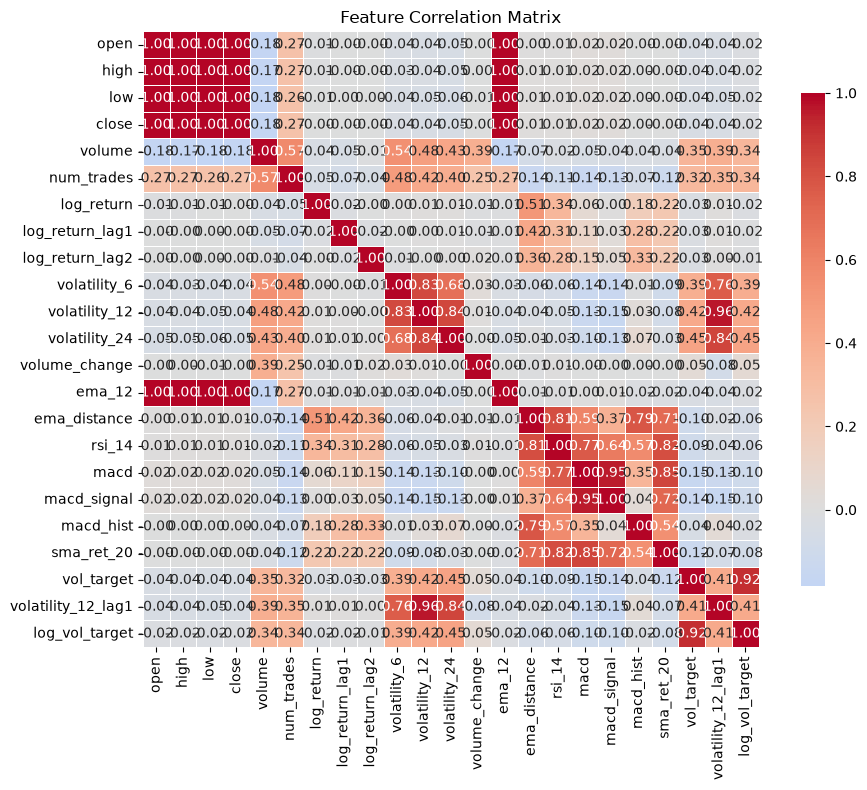

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix (only numeric columns, drop timestamp)
corr = df.drop(columns=['open_time']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [55]:
df

,open_time,open,high,low,close,volume,num_trades,log_return,log_return_lag1,log_return_lag2,...,volatility_24,volume_change,ema_12,ema_distance,rsi_14,macd,macd_signal,macd_hist,sma_ret_20,vol_target
0,2023-08-11 16:00:00,29395.90,29431.03,29252.45,29361.77,1938.53751,38138,-0.001161,-0.003381,0.000839,...,0.006196,0.112745,29423.522416,-61.752416,36.341790,-5.265367,-1.552223,-3.713145,-0.000156,0.002984
1,2023-08-11 17:00:00,29361.77,29397.36,29323.00,29340.40,621.02805,19518,-0.000728,-0.001161,-0.003381,...,0.006206,-0.679641,29410.734352,-70.334352,34.471443,-11.506188,-3.543016,-7.963172,-0.000214,0.002903
2,2023-08-11 18:00:00,29340.39,29377.60,29330.83,29376.19,417.16632,14916,0.001219,-0.000728,-0.001161,...,0.006284,-0.328265,29405.419837,-29.229837,40.037382,-13.409553,-5.516323,-7.893230,-0.000151,0.002691
3,2023-08-11 19:00:00,29376.20,29416.65,29350.67,29396.76,538.62086,16325,0.000700,0.001219,-0.000728,...,0.006323,0.291142,29404.087554,-7.327554,43.032358,-13.107066,-7.034472,-6.072594,-0.000100,0.002616
4,2023-08-11 20:00:00,29396.76,29429.00,29396.76,29420.22,320.47106,11491,0.000798,0.000700,0.001219,...,0.006372,-0.405016,29406.569469,13.650531,46.325133,-10.849253,-7.797428,-3.051825,-0.000104,0.002676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26239,2026-08-08 23:00:00,64950.62,64975.99,64936.01,64962.60,204.73811,22596,0.000185,-0.000959,-0.001068,...,0.003576,-0.520861,65020.880062,-58.280062,48.600101,37.446768,59.435603,-21.988835,-0.000054,0.002708
26240,2026-08-09 00:00:00,64962.60,64991.93,64958.17,64973.65,214.05253,18975,0.000170,0.000185,-0.000959,...,0.003578,0.045494,65013.613898,-39.963898,49.527695,30.905293,53.729541,-22.824248,-0.000031,0.002707
26241,2026-08-09 01:00:00,64973.65,65002.00,64838.33,64861.46,330.74593,31321,-0.001728,0.000170,0.000185,...,0.003980,0.545162,64990.205606,-128.745606,41.365441,16.478379,46.279308,-29.800929,-0.000103,0.004321
26242,2026-08-09 02:00:00,64861.46,64863.16,64777.92,64820.01,255.40052,32270,-0.000639,-0.001728,0.000170,...,0.004018,-0.227804,64964.021667,-144.011667,38.819947,1.680901,37.359627,-35.678726,-0.000144,0.004152


In [69]:
# ── volatility prediction setup: features + future realized-vol target ─────────────────
feature_cols = [
    'num_trades',
    "log_return_lag2",
    "log_return_lag1",
    "volatility_6",
    "volatility_12",
    "volatility_24",
    "volume_change",
    "ema_distance",
    "rsi_14",
    "macd_hist",
    "sma_ret_20",
    'volatility_12_lag1'
]


TARGET = "log_vol_target"

# Build X and y separately
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)

# Walk-forward chronological split: train -> validation -> test
# Keep the same feature columns and target variable, but split in time.
train_end = int(len(X) * 0.60)
val_end = int(len(X) * 0.80)

X_train_full = X[:train_end]
X_val_full = X[train_end:val_end]
X_test_full = X[val_end:]

y_train_full = y[:train_end]
y_val_full = y[train_end:val_end]
y_test_full = y[val_end:]

# Fit normalization on training data only
feature_mean = X_train_full.mean(axis=0)
feature_std = X_train_full.std(axis=0)
feature_std[feature_std == 0] = 1.0

X_train = (X_train_full - feature_mean) / feature_std
X_val = (X_val_full - feature_mean) / feature_std
X_test = (X_test_full - feature_mean) / feature_std

# Normalize target using training stats only
# This keeps regression scaling stable and avoids leakage.
target_mean = y_train_full.mean()
target_std = y_train_full.std()
if target_std == 0:
    target_std = 1.0

y_train = (y_train_full - target_mean) / target_std
y_val = (y_val_full - target_mean) / target_std
y_test = (y_test_full - target_mean) / target_std

# Sequence windows: X[t-window:t] -> y[t]
def make_windows(X_seq, y_seq, seq_len=30):
    Xw, yw = [], []
    for i in range(len(X_seq) - seq_len):
        Xw.append(X_seq[i:i + seq_len])
        yw.append(y_seq[i + seq_len])
    return np.asarray(Xw, dtype=np.float32), np.asarray(yw, dtype=np.float32)

X_train, y_train = make_windows(X_train, y_train, seq_len=10)
X_val, y_val = make_windows(X_val, y_val, seq_len=10)
X_test, y_test = make_windows(X_test, y_test, seq_len=10)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:", X_val.shape, " y_val:", y_val.shape)
print("X_test:", X_test.shape, " y_test:", y_test.shape)
print("first target samples:", y_train[:5])

X_train: (15671, 10, 12)  y_train: (15671,)
X_val: (5217, 10, 12)  y_val: (5217,)
X_test: (5218, 10, 12)  y_test: (5218,)
first target samples: [-0.9762089  -0.9362443  -0.9209164  -0.91039467 -0.89037097]


In [70]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [71]:
class Model(nn.Module):
    def __init__(self, input_size, hidden_size=8, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out[:, -1, :])
        return self.head(out)

In [72]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

In [73]:
model = Model(X_train.shape[-1], hidden_size=8, num_layers=2,dropout=0.2)
model
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 60
criterion = nn.HuberLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Huber")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/60 - train_loss: 0.335482 - val_loss: 0.344111
Epoch 2/60 - train_loss: 0.308510 - val_loss: 0.357531
Epoch 3/60 - train_loss: 0.302155 - val_loss: 0.357306
Epoch 4/60 - train_loss: 0.293778 - val_loss: 0.317530
Epoch 5/60 - train_loss: 0.289875 - val_loss: 0.369997
Epoch 6/60 - train_loss: 0.285617 - val_loss: 0.398647
Epoch 7/60 - train_loss: 0.279195 - val_loss: 0.374718
Epoch 8/60 - train_loss: 0.278244 - val_loss: 0.368873
Epoch 9/60 - train_loss: 0.274853 - val_loss: 0.366604
Epoch 10/60 - train_loss: 0.272795 - val_loss: 0.372075
Epoch 11/60 - train_loss: 0.266820 - val_loss: 0.383547


KeyboardInterrupt: 

In [67]:
model.eval()
criterion =  nn.MSELoss()
test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.792902


REALIZED VOLATILITY SPACE:
             Model | RMSE: 0.508484 | MAE: 0.401885
     Mean baseline | RMSE: 0.570284 | MAE: 0.446566
            HAR-RV | RMSE: 4.452591 | MAE: 4.417278

NORMALIZED TARGET SPACE:
             Model | RMSE: 0.865145
            HAR-RV | RMSE: 7.575725
     Mean baseline | RMSE: 4.270812


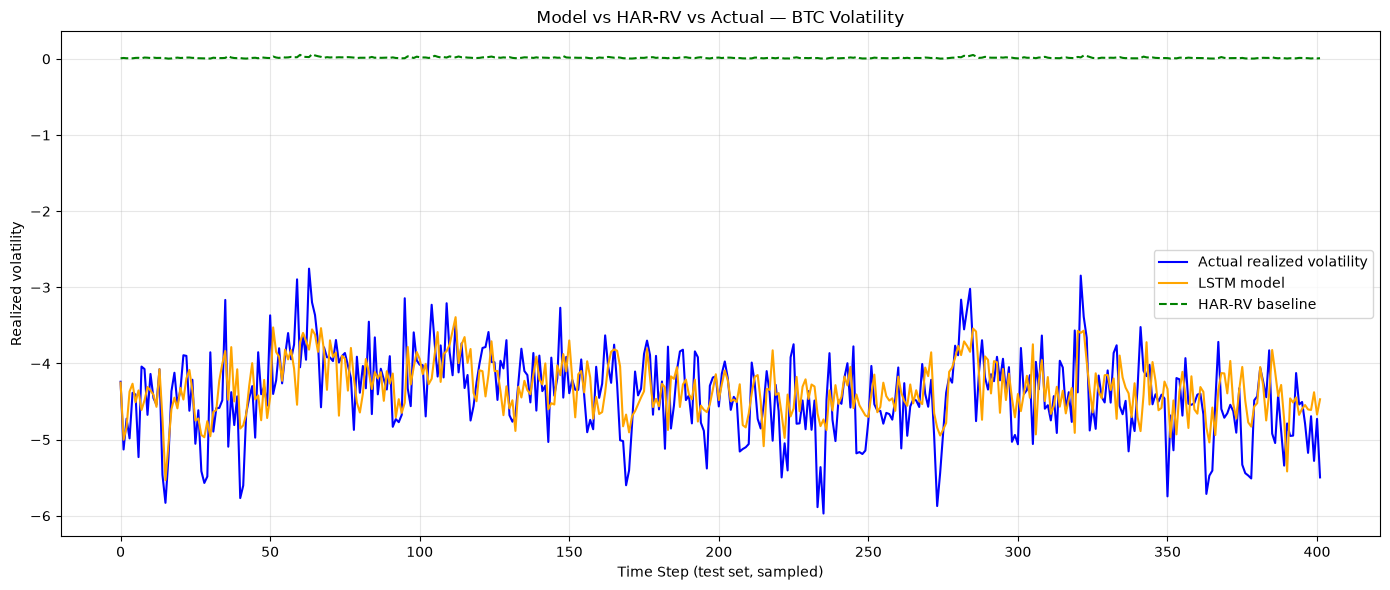

In [68]:
# ============================================================
# 1) Generate model predictions on the test set
# ============================================================
model.eval()
preds, actuals = [], []

with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        preds.append(pred)
        actuals.append(label)

preds = torch.cat(preds)
actuals = torch.cat(actuals)

# ============================================================
# 2) HAR-RV baseline
# ============================================================
# HAR-RV_t = (RV_6 + RV_12 + RV_24) / 3
har_pred = []
for i in range(len(y_test)):
    row = df.iloc[val_end + i + 9]
    rv_6 = row["volatility_6"]
    rv_12 = row["volatility_12"]
    rv_24 = row["volatility_24"]
    har_rv = (rv_6 + rv_12 + rv_24) / 3.0
    har_pred.append(har_rv)

har_pred = np.asarray(har_pred, dtype=np.float32)

# ============================================================
# 3) Undo normalization so everything is in actual volatility units
# ============================================================
pred_real = (preds * target_std + target_mean).cpu().numpy()
actual_real = (actuals * target_std + target_mean).cpu().numpy()

# mean baseline in same units
mean_baseline = y_train_full.mean()
mean_pred = np.full_like(actual_real, fill_value=mean_baseline, dtype=np.float32)

# ============================================================
# 4) Evaluation
# ============================================================
def eval_metrics(pred, actual, label):
    pred = np.asarray(pred, dtype=np.float32)
    actual = np.asarray(actual, dtype=np.float32)
    mae = np.abs(pred - actual).mean()
    rmse = np.sqrt(((pred - actual) ** 2).mean())
    print(f"{label:>18} | RMSE: {rmse:.6f} | MAE: {mae:.6f}")

print("REALIZED VOLATILITY SPACE:")
eval_metrics(pred_real, actual_real, "Model")
eval_metrics(mean_pred, actual_real, "Mean baseline")
eval_metrics(har_pred, actual_real, "HAR-RV")

# Optional normalized-space comparison
har_pred_scaled = (har_pred - target_mean) / target_std
har_pred_scaled = torch.tensor(har_pred_scaled, dtype=torch.float32)

model_rmse = ((preds - actuals) ** 2).mean().sqrt()
har_rmse = ((har_pred_scaled - actuals) ** 2).mean().sqrt()
mean_rmse = ((torch.tensor(mean_baseline, dtype=torch.float32) - actuals) ** 2).mean().sqrt()

print("\nNORMALIZED TARGET SPACE:")
print(f"{'Model':>18} | RMSE: {model_rmse.item():.6f}")
print(f"{'HAR-RV':>18} | RMSE: {har_rmse.item():.6f}")
print(f"{'Mean baseline':>18} | RMSE: {mean_rmse.item():.6f}")

# ============================================================
# 5) Plot a sampled version for readability
# ============================================================
import matplotlib.pyplot as plt

n_show = 400
stride = max(1, len(actual_real) // n_show)
plot_idx = np.arange(0, len(actual_real), stride)

pred_plot = pred_real[plot_idx]
actual_plot = actual_real[plot_idx]
har_plot = har_pred[plot_idx]

plt.figure(figsize=(14, 6))
plt.plot(actual_plot, label="Actual realized volatility", color="blue", linewidth=1.5)
plt.plot(pred_plot, label="LSTM model", color="orange", linewidth=1.5)
plt.plot(har_plot, label="HAR-RV baseline", color="green", linewidth=1.5, linestyle="--")
plt.xlabel("Time Step (test set, sampled)")
plt.ylabel("Realized volatility")
plt.title("Model vs HAR-RV vs Actual — BTC Volatility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,

    "training_loss": training_loss,
    "testing_loss": testing_loss,
}, "bitcoin_lstm_model_voltitity_v2.pt")



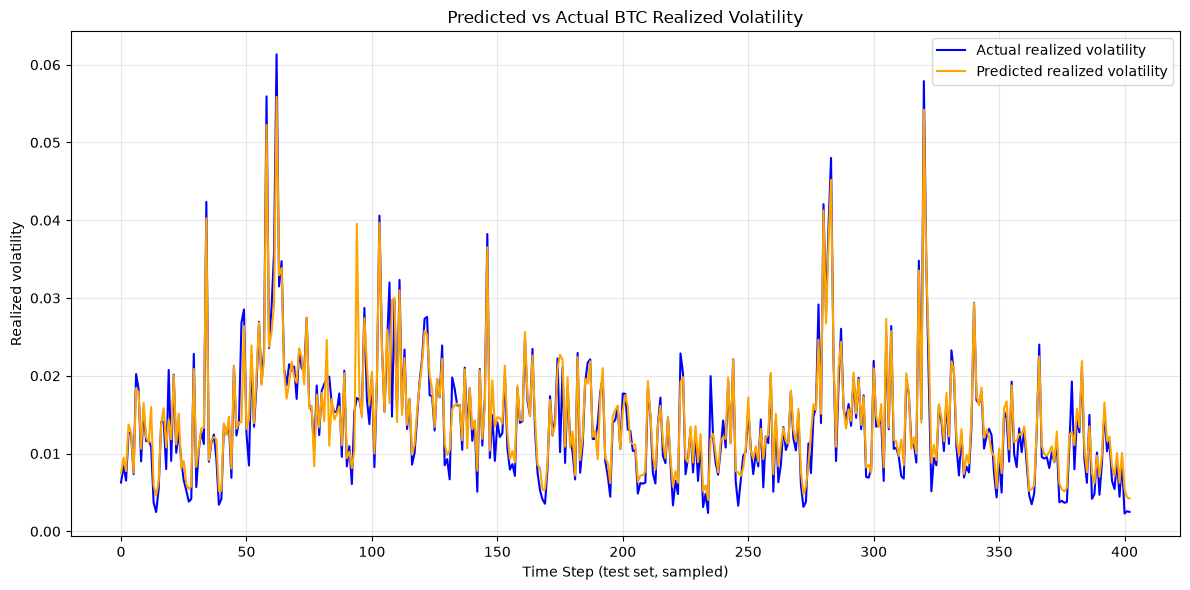

In [ ]:
import matplotlib.pyplot as plt

# Convert back to real realized-volatility space
pred_vol = preds * target_std + target_mean
actual_vol = actuals * target_std + target_mean

plt.figure(figsize=(12, 6))
plt.plot(actual_vol.detach().cpu().numpy(), label="Actual realized volatility", color="blue", linewidth=1.5)
plt.plot(pred_vol.detach().cpu().numpy(), label="Predicted realized volatility", color="orange", linewidth=1.5)
plt.xlabel("Time Step (test set)")
plt.ylabel("Realized volatility")
plt.title("Predicted vs Actual BTC Realized Volatility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


said HIGH, was HIGH: 2521
said HIGH, was LOW:  322
said LOW,  was HIGH: 98
said LOW,  was LOW:  2298
precision of HIGH calls: 88.7%
base rate (high-vol periods): 50.0%
overall accuracy: 92.0%


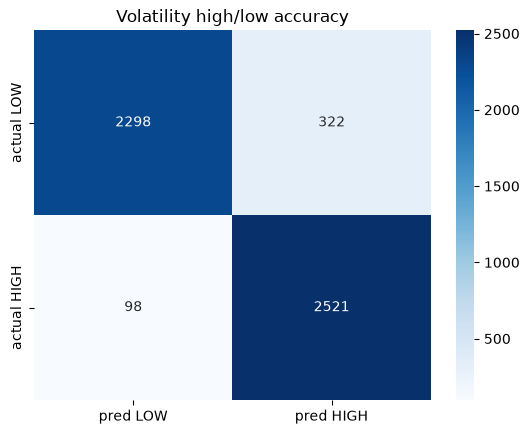

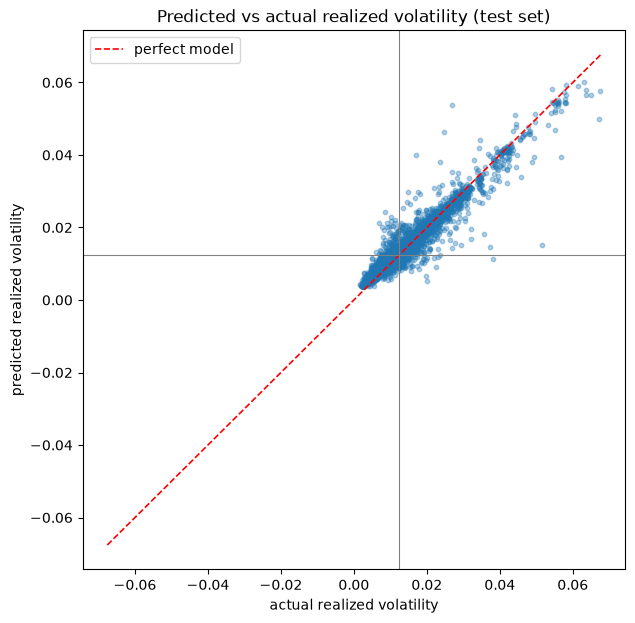

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

preds_arr = np.asarray(preds)
actuals_arr = np.asarray(actuals)

# convert back to realized-volatility space for visual comparison
pred_vol = preds_arr * target_std + target_mean
actual_vol = actuals_arr * target_std + target_mean

pred_up = pred_vol > np.median(actual_vol)
actual_up = actual_vol > np.median(actual_vol)

# confusion-style summary on volatility direction relative to median
# (useful as a coarse threshold check, not a probability calibration check)
tp = (pred_up & actual_up).sum()
fp = (pred_up & ~actual_up).sum()
fn = (~pred_up & actual_up).sum()
tn = (~pred_up & ~actual_up).sum()

print(f"said HIGH, was HIGH: {tp}")
print(f"said HIGH, was LOW:  {fp}")
print(f"said LOW,  was HIGH: {fn}")
print(f"said LOW,  was LOW:  {tn}")
print(f"precision of HIGH calls: {tp/(tp+fp):.1%}")
print(f"base rate (high-vol periods): {(actual_up.mean()):.1%}")
print(f"overall accuracy: {(tp+tn)/len(preds_arr):.1%}")

cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred LOW", "pred HIGH"],
            yticklabels=["actual LOW", "actual HIGH"])
plt.title("Volatility high/low accuracy")
plt.show()

# scatter plot in realized-volatility units
plt.figure(figsize=(7, 7))
plt.scatter(actual_vol, pred_vol, alpha=0.35, s=10)
lim = max(abs(actual_vol.min()), abs(actual_vol.max()),
          abs(pred_vol.min()), abs(pred_vol.max()))
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1.2, label="perfect model")
plt.axhline(np.median(actual_vol), color="gray", lw=0.8)
plt.axvline(np.median(actual_vol), color="gray", lw=0.8)
plt.xlabel("actual realized volatility")
plt.ylabel("predicted realized volatility")
plt.legend()
plt.title("Predicted vs actual realized volatility (test set)")
plt.show()


Real realized-volatility space (sampled view):
Showing 403 of 5239 test points
Model      | RMSE: 0.002334 | MAE: 0.001407
Persistence| RMSE: 0.009313 | MAE: 0.006545


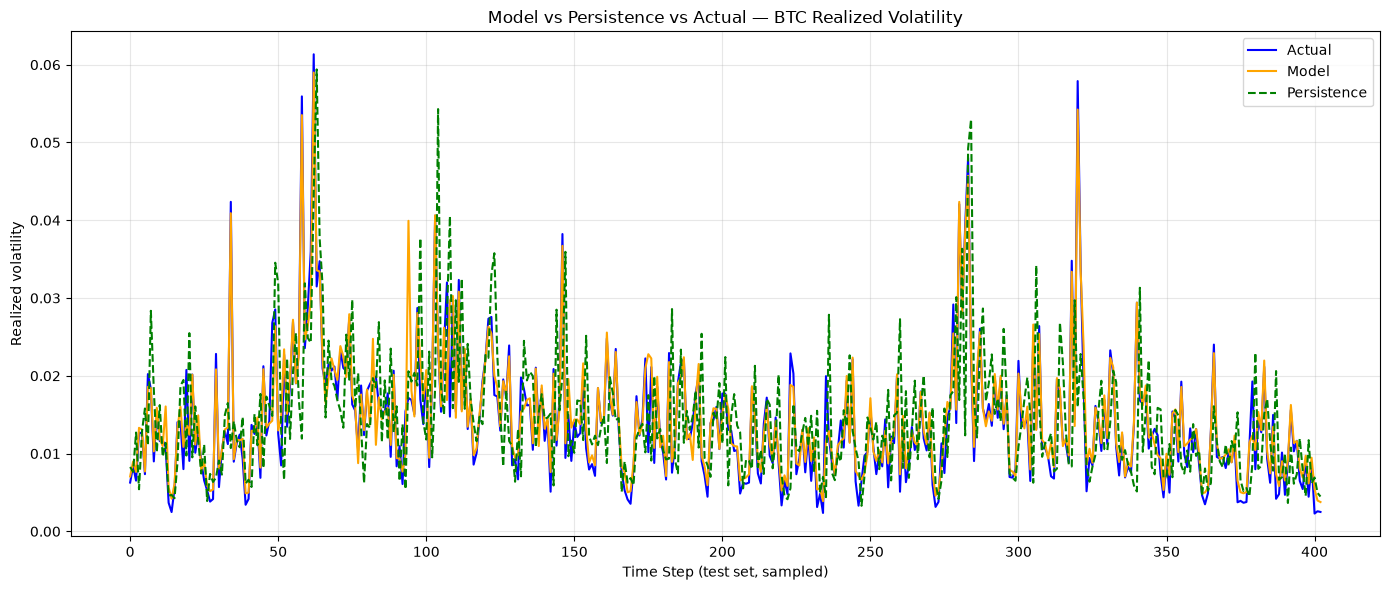

In [43]:
import matplotlib.pyplot as plt

# Use a smaller sample of the test period for readability
n_show = 400
stride = max(1, len(actuals) // n_show)
plot_idx = np.arange(0, len(actuals), stride)

pred_plot = (preds * target_std + target_mean).detach().cpu().numpy()[plot_idx]
actual_plot = (actuals * target_std + target_mean).detach().cpu().numpy()[plot_idx]
persist_plot = (X_test[:, -1, 3] * target_std + target_mean)[::stride]

print("Real realized-volatility space (sampled view):")
print(f"Showing {len(plot_idx)} of {len(actuals)} test points")

# Metrics on the full test set still remain the same
full_pred = (preds * target_std + target_mean).detach().cpu().numpy()
full_actual = (actuals * target_std + target_mean).detach().cpu().numpy()
full_persist = (X_test[:, -1, 3] * target_std + target_mean)

rmse_model = np.sqrt(((full_pred - full_actual) ** 2).mean())
rmse_persist = np.sqrt(((full_persist - full_actual) ** 2).mean())
mae_model = np.abs(full_pred - full_actual).mean()
mae_persist = np.abs(full_persist - full_actual).mean()
print(f"Model      | RMSE: {rmse_model:.6f} | MAE: {mae_model:.6f}")
print(f"Persistence| RMSE: {rmse_persist:.6f} | MAE: {mae_persist:.6f}")

# Plot the sampled subset only
plt.figure(figsize=(14, 6))
plt.plot(actual_plot, label="Actual", color="blue", linewidth=1.5)
plt.plot(pred_plot, label="Model", color="orange", linewidth=1.5)
plt.plot(persist_plot, label="Persistence", color="green", linewidth=1.5, linestyle="--")
plt.xlabel("Time Step (test set, sampled)")
plt.ylabel("Realized volatility")
plt.title("Model vs Persistence vs Actual — BTC Realized Volatility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
